# 04b · Isolation Forest, tuned

Notebook 04 used a default Isolation Forest (IF) on all features: PR-AUC 0.12 alone and no gain as a feature. Defaults
are a weak test of the idea, so here the choices that matter most for an isolation-based detector are tuned:

| Choice | Why it matters for Isolation Forest |
|---|---|
| **Feature set**: all 150 numeric features vs **behavioural activity only** (transactions, logins) | IF picks a *random* feature at every split; ~100 near-constant demographic flags waste splits and dilute the signal |
| **`log1p` transform** | split points are drawn uniformly between a feature's min and max, so heavy-tailed counts get split only near their extremes; log spreads the bulk of the distribution |
| **Fit on all accounts vs legit only** | fitting on known-legit accounts turns IF into a *novelty* detector ("learn normal, flag the rest"), the classic semi-supervised fraud set-up |
| `max_samples`, `max_features`, `n_estimators` | rows per tree (sub-sampling is what makes anomalies easy to isolate), features per tree, ensemble size |

**Tuning protocol.** Optuna (TPE, 100 trials) maximises **PR-AUC of out-of-fold anomaly scores on dev**: dev is split
in two halves; IF is fitted on one half (legit rows only when that option is chosen) and scores the other, so no
account is scored by a forest that saw it. Labels are used only to *choose* the configuration and, for the legit-only
option, to filter training rows. The holdout is used once at the end.

Then: (a) the tuned IF as a stand-alone detector on the holdout; (b) the tuned IF score as an extra feature for the
final XGBoost (3 seeds), computed label-free (see section 3).

In [1]:
import sys; sys.path.insert(0, '..')
import json, warnings
from time import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import optuna
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix
from src.data import DataLoader, TARGET
from src.features import FeatureBuilder
from src.model import XGBCV, PlattCalibrator, evaluate
from src.train import XGB_TUNED, WEIGHT_POWER

warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format, 'display.width', 200)

train = DataLoader().load('train')
y = train[TARGET]
X = FeatureBuilder().fit_transform(train)
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)
y_dev, y_hold = y.loc[idx_dev].to_numpy(), y.loc[idx_hold].to_numpy()

num = X.select_dtypes('number').columns
X_imp = X[num].fillna(X.loc[idx_dev, num].median())                  # IF needs complete data; medians from dev only
FEATURE_SETS = {'all': list(num),
                'activity': [c for c in num if c.startswith('txn_') or c in [f'others_{i}' for i in range(21, 27)]]}
print({k: len(v) for k, v in FEATURE_SETS.items()})

def matrix(feature_set, log):
    M = X_imp[FEATURE_SETS[feature_set]]
    return np.log1p(M.clip(lower=0)) if log else M

def make_iso(p, seed):
    return IsolationForest(n_estimators=p['n_estimators'], max_samples=p['max_samples'], max_features=p['max_features'],
                           random_state=seed, n_jobs=-1)

def oof_scores(p, rows, seed=0):
    """2-fold out-of-fold anomaly scores (higher = more anomalous) for `rows`."""
    M, yy = matrix(p['feature_set'], p['log']).loc[rows], y.loc[rows].to_numpy()
    out = np.zeros(len(rows))
    for a, b in StratifiedKFold(2, shuffle=True, random_state=seed).split(M, yy):
        fit_rows = a[yy[a] == 0] if p['fit_on'] == 'legit only' else a
        out[b] = -make_iso(p, seed).fit(M.iloc[fit_rows]).score_samples(M.iloc[b])
    return out

DEFAULT = dict(feature_set='all', log=False, fit_on='all', n_estimators=100, max_samples=256, max_features=1.0)
p_def = oof_scores(DEFAULT, idx_dev)
print(f'default IF (as in notebook 04): dev OOF PR-AUC {average_precision_score(y_dev, p_def):.4f}, ROC-AUC {roc_auc_score(y_dev, p_def):.4f}')

{'all': 150, 'activity': 79}


default IF (as in notebook 04): dev OOF PR-AUC 0.0918, ROC-AUC 0.7598


## 1. Tuning

In [2]:
def objective(trial):
    p = dict(feature_set=trial.suggest_categorical('feature_set', ['all', 'activity']),
             log=trial.suggest_categorical('log', [False, True]),
             fit_on=trial.suggest_categorical('fit_on', ['all', 'legit only']),
             n_estimators=trial.suggest_int('n_estimators', 100, 500, step=50),
             max_samples=trial.suggest_int('max_samples', 128, 8192, log=True),
             max_features=trial.suggest_float('max_features', .1, 1.0))
    s = oof_scores(p, idx_dev)
    trial.set_user_attr('roc_auc', roc_auc_score(y_dev, s))
    return average_precision_score(y_dev, s)

t = time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial({**DEFAULT})
study.optimize(objective, n_trials=100)
best = {**study.best_params}
print(f'{len(study.trials)} trials in {(time() - t) / 60:.1f} min | default PR-AUC {study.trials[0].value:.4f} -> best {study.best_value:.4f} '
      f'(ROC-AUC {study.best_trial.user_attrs["roc_auc"]:.4f})')
print('best config:', json.dumps(best, indent=1))

100 trials in 3.1 min | default PR-AUC 0.0918 -> best 0.2884 (ROC-AUC 0.8432)
best config: {
 "feature_set": "activity",
 "log": false,
 "fit_on": "legit only",
 "n_estimators": 250,
 "max_samples": 3676,
 "max_features": 0.6786597920762075
}


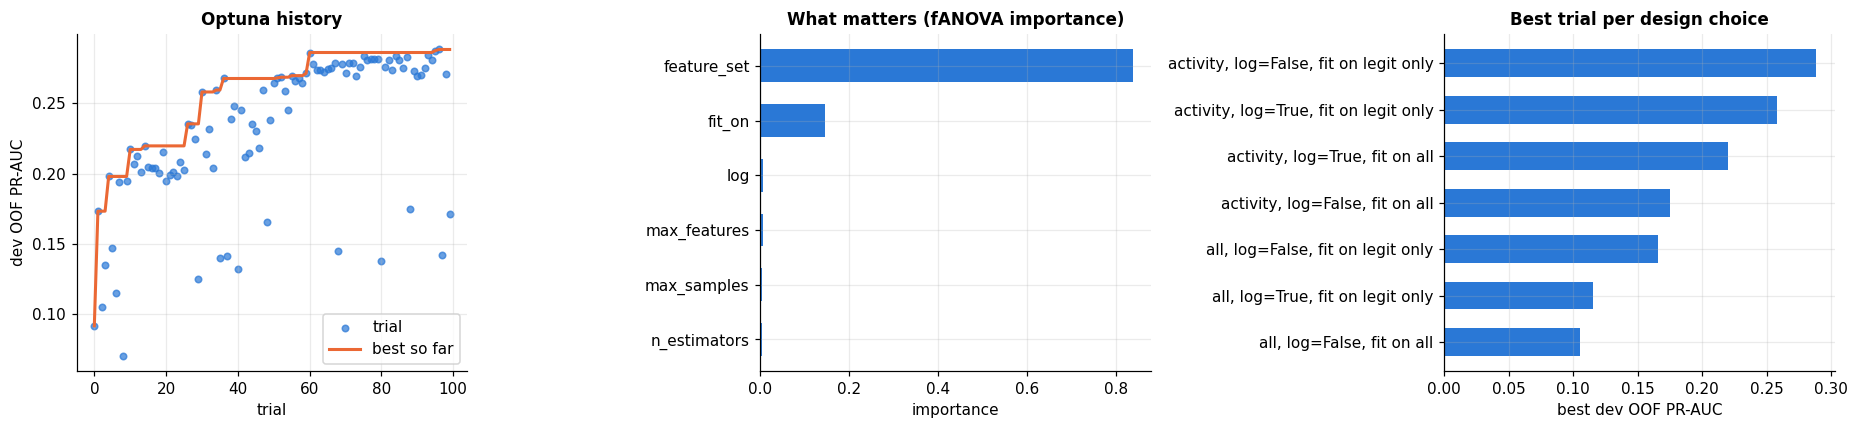

In [3]:
vals = study.trials_dataframe()
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(vals.number, vals.value, s=18, color=BLUE, alpha=.7, label='trial')
axes[0].plot(vals.number, vals.value.cummax(), color=ORANGE, lw=2, label='best so far')
axes[0].set(xlabel='trial', ylabel='dev OOF PR-AUC', title='Optuna history'); axes[0].legend()
imp = optuna.importance.get_param_importances(study)
axes[1].barh(list(imp)[::-1], list(imp.values())[::-1], color=BLUE, height=.6)
axes[1].set(title='What matters (fANOVA importance)', xlabel='importance')
g = vals.groupby(['params_feature_set', 'params_log', 'params_fit_on']).value.max().sort_values()
axes[2].barh([f'{a}, log={b}, fit on {c}' for a, b, c in g.index], g.values, color=BLUE, height=.6)
axes[2].set(xlabel='best dev OOF PR-AUC', title='Best trial per design choice')
plt.tight_layout(); plt.show()

## 2. Tuned Isolation Forest as a stand-alone detector (holdout)
Fitted on all dev rows (legit-only if chosen), scores the holdout; Platt calibration on the dev OOF scores.
Three forests with different seeds give mean ± std.

In [4]:
def holdout_eval(p, name):
    rows = []
    for s in (0, 1, 2):
        M = matrix(p['feature_set'], p['log'])
        fit = M.loc[idx_dev][y_dev == 0] if p['fit_on'] == 'legit only' else M.loc[idx_dev]
        sh = -make_iso(p, s).fit(fit).score_samples(M.loc[idx_hold])
        so = oof_scores(p, idx_dev, seed=s)
        cal = PlattCalibrator().fit(so, y_dev)
        rows.append((cal.predict(so), cal.predict(sh)))
    r = pd.DataFrame([{**{f'oof_{k}': v for k, v in evaluate(y_dev, o).items()}, **{f'hold_{k}': v for k, v in evaluate(y_hold, h).items()}} for o, h in rows])
    return pd.concat([r.mean(), r.std().add_suffix('_std')]).rename(name), rows

res_def, runs_def = holdout_eval(DEFAULT, 'IF default')
res_tuned, runs_tuned = holdout_eval(best, 'IF tuned')
standalone = pd.concat([res_def, res_tuned], axis=1).T
standalone[['oof_pr_auc', 'oof_roc_auc', 'hold_pr_auc', 'hold_pr_auc_std', 'hold_roc_auc', 'hold_log_loss']]

,oof_pr_auc,oof_roc_auc,hold_pr_auc,hold_pr_auc_std,hold_roc_auc,hold_log_loss
IF default,0.1065,0.7603,0.1424,0.0071,0.7752,0.0850
IF tuned,0.2783,0.8444,0.2985,0.0085,0.8474,0.0766


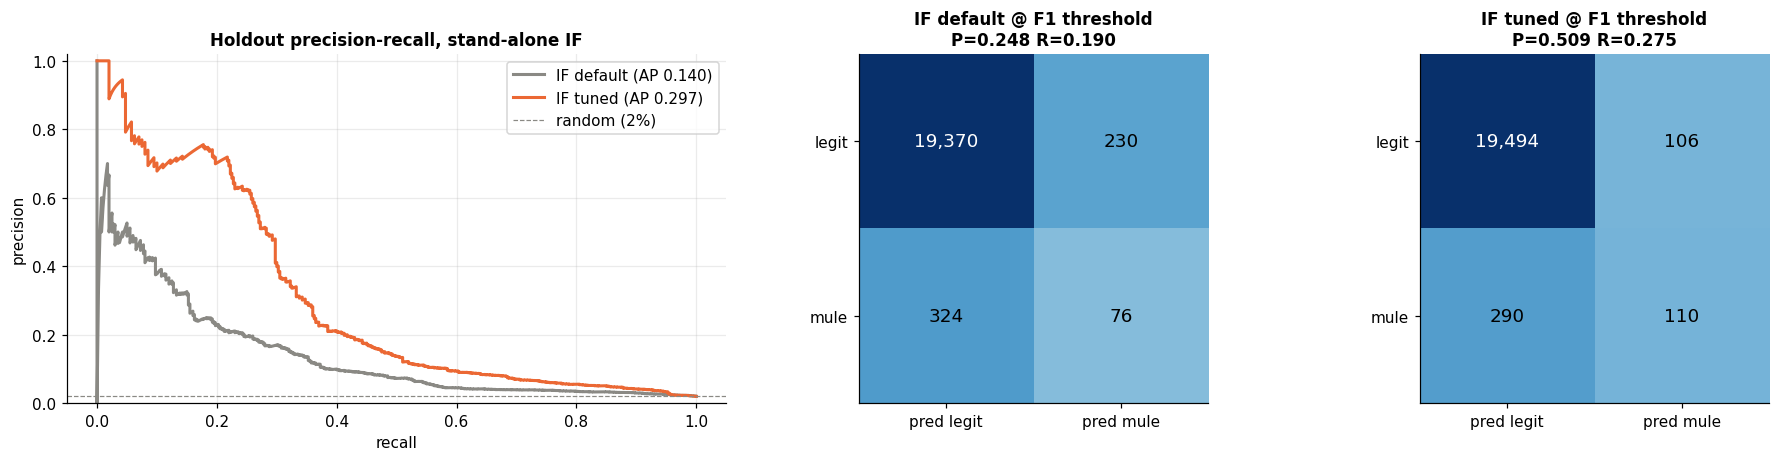

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={'width_ratios': [1.3, 1, 1]})
for name, runs, col in [('IF default', runs_def, GRAY), ('IF tuned', runs_tuned, ORANGE)]:
    pr, rc, _ = precision_recall_curve(y_hold, runs[-1][1])
    axes[0].plot(rc, pr, color=col, lw=2, label=f'{name} (AP {average_precision_score(y_hold, runs[-1][1]):.3f})')
axes[0].axhline(y_hold.mean(), color=GRAY, ls='--', lw=.8, label='random (2%)')
axes[0].set(xlabel='recall', ylabel='precision', ylim=(0, 1.02), title='Holdout precision-recall, stand-alone IF'); axes[0].legend()
for ax, (name, runs) in zip(axes[1:], [('IF default', runs_def), ('IF tuned', runs_tuned)]):
    oof, hold = runs[-1]
    pr, rc, thr = precision_recall_curve(y_dev, oof)
    t_ = thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]
    cm = confusion_matrix(y_hold, hold >= t_)
    ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=12, color='white' if v > 1000 else 'black')
    tn, fp, fn, tp = cm.ravel()
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'],
           title=f'{name} @ F1 threshold\nP={tp / max(tp + fp, 1):.3f} R={tp / (tp + fn):.3f}')
plt.tight_layout(); plt.show()

## 3. Tuned IF score as a feature for the final XGBoost
A feature fed to the supervised model must not carry label information across CV folds. The **label-free** version of
the tuned configuration (same feature set / transform / sizes, fitted on *all* dev rows, no label filtering)
satisfies this trivially: no label is used to compute it, so it can be computed once for every row.
(The legit-only variant uses labels to choose training rows, so it would need nested fitting inside every CV fold
to be leak-free. If label-free matches it stand-alone, the simpler option is preferred anyway.)

In [6]:
label_free = {**best, 'fit_on': 'all'}
res_lf, _ = holdout_eval(label_free, 'IF tuned, label-free')
print(f"stand-alone, label-free version: holdout PR-AUC {res_lf.hold_pr_auc:.4f} (vs {res_tuned.hold_pr_auc:.4f} for the chosen config)")
M = matrix(label_free['feature_set'], label_free['log'])
iso_feat = pd.Series(-make_iso(label_free, 0).fit(M.loc[idx_dev]).score_samples(M), index=X.index, name='iso_score')

RESULTS, RUNS = {}, {}
def run(name, Xv, seeds=(0, 1, 2)):
    t, runs, rows = time(), [], []
    for s in seeds:
        cv = XGBCV(XGB_TUNED, weight_power=WEIGHT_POWER, seed=s).fit(Xv.loc[idx_dev], y_dev)
        cal = PlattCalibrator().fit(cv.oof_, y_dev)
        o, h = cal.predict(cv.oof_), cal.predict(cv.predict_proba(Xv.loc[idx_hold]))
        runs.append((o, h)); rows.append({**{f'oof_{k}': v for k, v in evaluate(y_dev, o).items()}, **{f'hold_{k}': v for k, v in evaluate(y_hold, h).items()}})
    r = pd.DataFrame(rows); RESULTS[name], RUNS[name] = pd.concat([r.mean(), r.std().add_suffix('_std')]), runs
    m = RESULTS[name]
    print(f'{name:<30} OOF PR-AUC {m.oof_pr_auc:.4f}±{m.oof_pr_auc_std:.4f}  log-loss {m.oof_log_loss:.5f}±{m.oof_log_loss_std:.5f}'
          f' | holdout PR-AUC {m.hold_pr_auc:.4f}  log-loss {m.hold_log_loss:.5f} | {time() - t:.0f}s')
    return cv

run('final XGBoost', X)
cv_iso = run('final XGBoost + tuned IF score', X.join(iso_feat))
imp = cv_iso.feature_importance('gain')
print(f"iso_score rank by gain: {list(imp.index).index('iso_score') + 1} of {len(imp)} ({imp['iso_score'] / imp.sum():.1%} of total gain)")

stand-alone, label-free version: holdout PR-AUC 0.2052 (vs 0.2985 for the chosen config)


final XGBoost                  OOF PR-AUC 0.9489±0.0009  log-loss 0.01290±0.00009 | holdout PR-AUC 0.9533  log-loss 0.01251 | 199s


final XGBoost + tuned IF score OOF PR-AUC 0.9486±0.0012  log-loss 0.01294±0.00013 | holdout PR-AUC 0.9527  log-loss 0.01257 | 176s
iso_score rank by gain: 38 of 101 (0.8% of total gain)


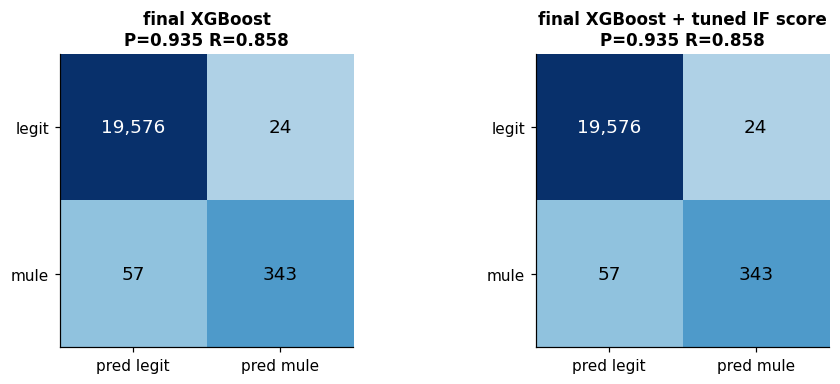

,oof_pr_auc,oof_pr_auc_std,oof_log_loss,oof_log_loss_std,hold_pr_auc,hold_log_loss
final XGBoost,0.9489,0.0009,0.0129,0.0001,0.9533,0.0125
final XGBoost + tuned IF score,0.9486,0.0012,0.0129,0.0001,0.9527,0.0126


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, n in zip(axes, RESULTS):
    oof, hold = RUNS[n][-1]
    pr, rc, thr = precision_recall_curve(y_dev, oof)
    t_ = thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]
    cm = confusion_matrix(y_hold, hold >= t_)
    ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=12, color='white' if v > 1000 else 'black')
    tn, fp, fn, tp = cm.ravel()
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'],
           title=f'{n}\nP={tp / max(tp + fp, 1):.3f} R={tp / (tp + fn):.3f}')
plt.tight_layout(); plt.show()
pd.DataFrame(RESULTS).T[['oof_pr_auc', 'oof_pr_auc_std', 'oof_log_loss', 'oof_log_loss_std', 'hold_pr_auc', 'hold_log_loss']]

## 4. Conclusions

| Result | Why | Decision |
|---|---|---|
| **Tuning doubles stand-alone performance**: holdout PR-AUC 0.142 → **0.299** (ROC-AUC 0.775 → 0.847, log-loss 0.085 → 0.077) | — | — |
| **What mattered: the feature set** (fANOVA importance 0.84). Activity-only (79 transaction / login columns) beats all 150 features | IF picks a random feature at each split; the ~70 demographic flags are near-constant, so splits on them isolate nothing and dilute the forest | key design lesson for IF |
| **Fitting on legit accounts only** helps (importance 0.15; best legit-only 0.29 vs best fit-on-all 0.22) | novelty detection: with no mules in the training sample, the forest learns "normal" more cleanly | used for the stand-alone detector |
| `log1p`, `max_samples`, `max_features`, `n_estimators` barely matter | IF is robust to these once the feature set is right | — |
| **Still ~3× below the supervised model** (PR-AUC 0.30 vs 0.95) | "unusual" ≠ "mule": very active, wealthy or foreign legit customers are just as unusual | not a replacement |
| **As a feature for the final XGBoost: no gain** (OOF log-loss 0.01294 vs 0.01290; 0.8% of gain). Label-free variant used, holdout PR-AUC 0.205 alone | the supervised model already learns the unusual activity patterns that matter, using the labels directly | not shipped |

**Where Isolation Forest *would* earn its place:** as a monitoring complement, not a model feature. (1) **Cold start**: a
new product with no labelled mules yet. (2) **Novel patterns**: mule behaviour that changes faster than labels arrive,
where an anomaly score can surface accounts the supervised model (trained on past mules) would miss.